<a href="https://colab.research.google.com/github/Renanzitto/samu_recife/blob/main/samu_recife.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ==========================================
# Download, Auditoria e Tratamento - SAMU Recife
# ==========================================

!pip install pandas numpy matplotlib seaborn plotly requests statsmodels scikit-learn openpyxl -q

import hashlib
import io
from pathlib import Path

import numpy as np
import pandas as pd
import requests

# ------------------------------------------
# Estrutura de pastas
# ------------------------------------------
BASE = Path('/content/samu')
for pasta in ['dados_brutos', 'dados_tratados', 'resultados']:
    (BASE / pasta).mkdir(parents=True, exist_ok=True)

# ------------------------------------------
# 1) Download via API do portal (CKAN) - não depende de links fixos
# ------------------------------------------
PORTAL = "https://dados.recife.pe.gov.br"
ANOS = range(2020, 2026)
HEADERS = {"User-Agent": "Mozilla/5.0 (compatible; Colab-SAMU/1.0)"}

# Fallback: IDs de recurso já confirmados no portal (solicitações)
IDS_CONHECIDOS = {
    2024: "142cbf53-86ae-4e09-bae6-da9cbd448184",
    2025: "7f15a2b4-2bfa-4238-8dbb-cf2409d8ca25",
}


def parece_html(conteudo: bytes) -> bool:
    inicio = conteudo[:2000].decode('utf-8', errors='ignore').lstrip().lower()
    return inicio.startswith('<!doctype') or inicio.startswith('<html') or '<html' in inicio[:500]


def candidatos_download(ano):
    """Gera URLs possíveis para o CSV de solicitações do ano, da mais provável à menos."""
    urls = []
    slug = f"servico-de-atendimento-movel-de-urgencia-samu-{ano}"
    try:
        r = requests.get(f"{PORTAL}/api/3/action/package_show", params={"id": slug},
                         headers=HEADERS, timeout=60)
        r.raise_for_status()
        recursos = r.json()["result"]["resources"]
        print(f"  Recursos do dataset {ano}: {[x.get('name') for x in recursos]}")
        csvs = [x for x in recursos if str(x.get("format", "")).upper() == "CSV"]
        # prioriza recursos de "solicitações"
        csvs.sort(key=lambda x: "solicit" not in (str(x.get("name")) + str(x.get("description"))).lower())
        for x in csvs:
            if x.get("url"):
                urls.append(x["url"])
            urls.append(f"{PORTAL}/datastore/dump/{x['id']}?format=csv&bom=true")
    except Exception as e:
        print(f"  [aviso] API do portal falhou para {ano}: {e}")
    if ano in IDS_CONHECIDOS:
        urls.append(f"{PORTAL}/datastore/dump/{IDS_CONHECIDOS[ano]}?format=csv&bom=true")
    return urls


arquivos_baixados = {}

for ano in ANOS:
    print(f"Buscando {ano}...")
    caminho_local = BASE / 'dados_brutos' / f'samu_{ano}.csv'
    for url in candidatos_download(ano):
        try:
            resp = requests.get(url, headers=HEADERS, timeout=180, allow_redirects=True)
            resp.raise_for_status()
            conteudo = resp.content
            if not conteudo or parece_html(conteudo):
                print(f"  [falhou] conteúdo vazio/HTML em {url}")
                continue
            caminho_local.write_bytes(conteudo)
            sha = hashlib.sha256(conteudo).hexdigest()
            print(f"[OK] Ano {ano} | {len(conteudo)/1e6:.1f} MB | SHA-256: {sha[:16]}...")
            arquivos_baixados[ano] = caminho_local
            break
        except Exception as e:
            print(f"  [falhou] {url} -> {e}")
    else:
        print(f"[ERRO] Ano {ano}: nenhum link funcionou.")

faltando = [a for a in ANOS if a not in arquivos_baixados]
if faltando:
    print(f"\nAnos faltando: {faltando}")
    print("Baixe manualmente em dados.recife.pe.gov.br (busque 'SAMU <ano>', recurso 'Solicitações de Atendimento'),")
    print("e envie com o bloco abaixo (descomente):")
    # from google.colab import files
    # up = files.upload()
    # for nome in up: Path(nome).rename(BASE / 'dados_brutos' / nome)
    # Depois renomeie cada arquivo para samu_ANO.csv e rode novamente.

if not arquivos_baixados:
    raise RuntimeError("Nenhum arquivo foi baixado. Veja as mensagens acima.")


# ------------------------------------------
# 2) Leitura robusta (encoding + separador)
# ------------------------------------------
def ler_csv_robusto(caminho: Path) -> pd.DataFrame:
    ultimo_erro = None
    for enc in ('utf-8-sig', 'utf-8', 'latin-1'):
        try:
            df = pd.read_csv(caminho, sep=None, engine='python', encoding=enc,
                             dtype=str, on_bad_lines='warn')
            if df.shape[1] > 1:
                return df
        except Exception as e:
            ultimo_erro = e
    raise ValueError(f"Não foi possível ler {caminho.name}: {ultimo_erro}")


def achar_coluna(df, preferidas, contem=None):
    """Procura primeiro nome exato (sem acento/caixa), depois por trecho."""
    norm = {c: c.lower().strip()
              .replace('í', 'i').replace('ê', 'e').replace('ç', 'c')
              .replace('ã', 'a').replace('é', 'e').replace('á', 'a')
            for c in df.columns}
    for p in preferidas:
        for original, n in norm.items():
            if n == p:
                return original
    for trecho in (contem or []):
        for original, n in norm.items():
            if trecho in n:
                return original
    return None


def extrair_idade(serie: pd.Series) -> pd.Series:
    """Extrai idade em anos de textos como '30', '30 anos', '5 meses'."""
    s = serie.astype(str).str.lower()
    num = pd.to_numeric(s.str.extract(r'(\d+[.,]?\d*)')[0].str.replace(',', '.'), errors='coerce')
    em_meses = s.str.contains(r'mes|mês', regex=True, na=False)
    em_dias = s.str.contains(r'dia', na=False)
    num = num.where(~(em_meses | em_dias), 0)  # bebê < 1 ano => 0
    return num.where((num >= 0) & (num <= 120))  # fora disso = inválido


def parse_datas(serie: pd.Series) -> pd.Series:
    """Converte datas em ISO (AAAA-MM-DD...) e BR (DD/MM/AAAA...) separadamente,
    evitando que um formato contamine a interpretação do outro."""
    s = serie.astype(str).str.strip()
    resultado = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')
    iso = s.str.match(r'^\d{4}-\d{1,2}-\d{1,2}')
    br = s.str.match(r'^\d{1,2}[/.-]\d{1,2}[/.-]\d{4}')
    if iso.any():
        resultado[iso] = pd.to_datetime(s[iso].str[:19], format='ISO8601', errors='coerce')
    if br.any():
        resultado[br] = pd.to_datetime(s[br], dayfirst=True, format='mixed', errors='coerce')
    return resultado


# ------------------------------------------
# 3) Processamento e auditoria
# ------------------------------------------
bins = [0, 2, 6, 13, 19, 45, 65, np.inf]
labels = ['[0,2)', '[2,6)', '[6,13)', '[13,19)', '[19,45)', '[45,65)', '[65,+)']

auditoria_dados = []
dfs_processados = []

for ano, caminho in arquivos_baixados.items():
    print(f"\nProcessando e auditando dados de {ano}...")
    df_raw = ler_csv_robusto(caminho)
    df_raw.columns = [c.strip() for c in df_raw.columns]
    linhas_brutas = len(df_raw)
    print(f"  Colunas: {df_raw.columns.tolist()}")

    df = df_raw.copy()
    df['ano_arquivo'] = ano
    df['arquivo_origem'] = f"samu_{ano}.csv"

    col_data = achar_coluna(df, ['data', 'data_solicitacao', 'data_da_solicitacao'], ['data'])
    col_municipio = achar_coluna(df, ['municipio', 'cidade'], ['municipio', 'cidade'])
    col_subtipo = achar_coluna(df, ['subtipo', 'sub_tipo'], ['subtipo'])
    if col_subtipo is None:
        col_subtipo = achar_coluna(df, ['tipo'], ['tipo'])
    col_idade = achar_coluna(df, ['idade'], ['idade'])
    print(f"  Detectado -> data: {col_data} | município: {col_municipio} | "
          f"subtipo: {col_subtipo} | idade: {col_idade}")

    # Duplicatas exatas (linha inteira idêntica) - apenas sinalizadas, não removidas
    df['duplicata_sinalizada'] = df_raw.duplicated(keep='first').values

    # Recorte geográfico: palavra "RECIFE" no município
    if col_municipio:
        mask = df[col_municipio].astype(str).str.upper().str.contains(r'\bRECIFE\b', regex=True, na=False)
        df_recife = df[mask].copy()
        if df_recife.empty:
            print(f"  [ALERTA] Filtro 'RECIFE' zerou {ano}. Valores em '{col_municipio}':")
            print(df[col_municipio].value_counts().head(10).to_string())
    else:
        print("  [ALERTA] Coluna de município não encontrada; mantendo todas as linhas.")
        df_recife = df.copy()

    # Datas
    if col_data:
        df_recife['data_trata'] = parse_datas(df_recife[col_data])
    else:
        df_recife['data_trata'] = pd.NaT
    nat_count = int(df_recife['data_trata'].isna().sum())

    # DIAGNÓSTICO de datas: mostra o que a coluna tem e o que falhou
    if col_data:
        print(f"  [datas] coluna usada: '{col_data}' | exemplos: {df_recife[col_data].dropna().head(3).tolist()}")
        invalidas = df_recife.loc[df_recife['data_trata'].isna(), col_data]
        if len(invalidas):
            print(f"  [datas] {len(invalidas)} inválidas ({len(invalidas)/max(len(df_recife),1):.1%}). "
                  f"Exemplos: {invalidas.dropna().astype(str).unique()[:5].tolist()} | vazias: {int(invalidas.isna().sum())}")
        dt = df_recife['data_trata'].dropna()
        if len(dt):
            print(f"  [datas] mês/dia máx. encontrado: dia {dt.dt.day.max()} | "
                  f"distribuição por mês: {dt.dt.month.value_counts().sort_index().to_dict()}")

    # Indicador COVID (2020 usa "SCOVID" conforme mapeamento do projeto)
    if col_subtipo:
        txt = df_recife[col_subtipo].astype(str).str.upper()
        termo = "SCOVID" if ano == 2020 else "COVID"
        df_recife['indicador_covid'] = txt.str.contains(termo, na=False)
    else:
        df_recife['indicador_covid'] = False

    # Idade e faixa etária
    if col_idade:
        df_recife['idade_num'] = extrair_idade(df_recife[col_idade])
    else:
        df_recife['idade_num'] = np.nan
    ausencias_idade = int(df_recife['idade_num'].isna().sum())

    faixa = pd.cut(df_recife['idade_num'], bins=bins, labels=labels, right=False)
    df_recife['faixa_etaria'] = faixa.astype(object).where(faixa.notna(), 'Não informado / Inválido')

    # Tabela de auditoria
    datas_ok = df_recife['data_trata'].dropna()
    auditoria_dados.append({
        'ano': ano,
        'linhas_brutas': linhas_brutas,
        'linhas_finais': len(df_recife),
        'datas_invalidas': nat_count,
        'ausencias_idade': ausencias_idade,
        'duplicatas_sinalizadas': int(df_recife['duplicata_sinalizada'].sum()),
        'registros_covid': int(df_recife['indicador_covid'].sum()),
        'data_min': datas_ok.min().strftime('%Y-%m-%d') if not datas_ok.empty else 'N/A',
        'data_max': datas_ok.max().strftime('%Y-%m-%d') if not datas_ok.empty else 'N/A',
    })
    dfs_processados.append(df_recife)

# ------------------------------------------
# 4) Exportação
# ------------------------------------------
df_auditoria = pd.DataFrame(auditoria_dados)
print("\n--- TABELA DE AUDITORIA CONSOLIDADA ---")
try:
    display(df_auditoria)
except NameError:
    print(df_auditoria.to_string(index=False))

df_auditoria.to_csv(BASE / 'resultados' / 'tabela_auditoria.csv', index=False)

df_final = pd.concat(dfs_processados, ignore_index=True)
df_final.to_csv(BASE / 'dados_tratados' / 'samu_recife_tratado.csv', index=False)
print(f"\nBase tratada: {len(df_final)} linhas -> {BASE / 'dados_tratados' / 'samu_recife_tratado.csv'}")
print("Processamento concluído com sucesso!")

Buscando 2020...
  Recursos do dataset 2020: ['Solicitações de Atendimento 2020', 'Dicionário de Dados - Chamados Samu 2020']
[OK] Ano 2020 | 30.9 MB | SHA-256: f048ef4c768f506a...
Buscando 2021...
  Recursos do dataset 2021: ['Solicitações de Atendimento 2021', 'Dicionário de Dados - Chamados Samu 2021']
[OK] Ano 2021 | 35.1 MB | SHA-256: 5ca05300d3beded5...
Buscando 2022...
  Recursos do dataset 2022: ['Solicitações de Atendimento 2022', 'Dicionário de Dados - Chamados Samu 2022']
[OK] Ano 2022 | 33.1 MB | SHA-256: 26fbb38434b51c02...
Buscando 2023...
  Recursos do dataset 2023: ['Solicitações de Atendimento 2023', 'Dicionário de Dados - Chamados Samu 2023']
[OK] Ano 2023 | 33.5 MB | SHA-256: c8a7b7bc31ac6030...
Buscando 2024...
  Recursos do dataset 2024: ['Solicitações de Atendimento 2024', 'Dicionário de Dados - Chamados Samu 2024']
[OK] Ano 2024 | 40.2 MB | SHA-256: af011c3fe4206105...
Buscando 2025...
  Recursos do dataset 2025: ['Dicionário de Dados - Chamados Samu 2025', 'Soli

,ano,linhas_brutas,linhas_finais,datas_invalidas,ausencias_idade,duplicatas_sinalizadas,registros_covid,data_min,data_max
0,2020,193524,76089,0,1109,2,9336,2020-01-01,2020-12-31
1,2021,201022,78045,0,597,26,11612,2021-01-01,2021-12-31
2,2022,188609,71465,0,1586,55,2119,2022-01-01,2022-12-31
3,2023,189574,73775,0,3855,31,218,2023-01-01,2023-12-31
4,2024,222651,87757,0,8489,12470,69,2024-01-01,2024-12-31
5,2025,190087,73735,0,9117,65,9,2025-01-01,2025-12-31



Base tratada: 460866 linhas -> /content/samu/dados_tratados/samu_recife_tratado.csv
Processamento concluído com sucesso!


In [2]:
print(df_auditoria.T.to_string())

                                 0           1           2           3           4           5
ano                           2020        2021        2022        2023        2024        2025
linhas_brutas               193524      201022      188609      189574      222651      190087
linhas_finais                76089       78045       71465       73775       87757       73735
datas_invalidas                  0           0           0           0           0           0
ausencias_idade               1109         597        1586        3855        8489        9117
duplicatas_sinalizadas           2          26          55          31       12470          65
registros_covid               9336       11612        2119         218          69           9
data_min                2020-01-01  2021-01-01  2022-01-01  2023-01-01  2024-01-01  2025-01-01
data_max                2020-12-31  2021-12-31  2022-12-31  2023-12-31  2024-12-31  2025-12-31


In [3]:
print(df_final['indicador_covid'].groupby(df_final['ano_arquivo']).agg(['sum', 'mean']))

               sum      mean
ano_arquivo                 
2020          9336  0.122698
2021         11612  0.148786
2022          2119  0.029651
2023           218  0.002955
2024            69  0.000786
2025             9  0.000122


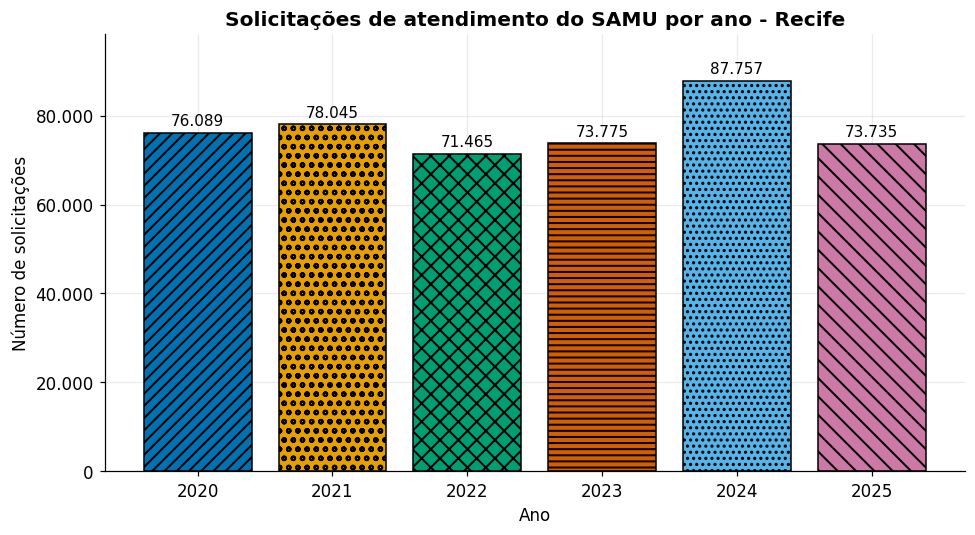

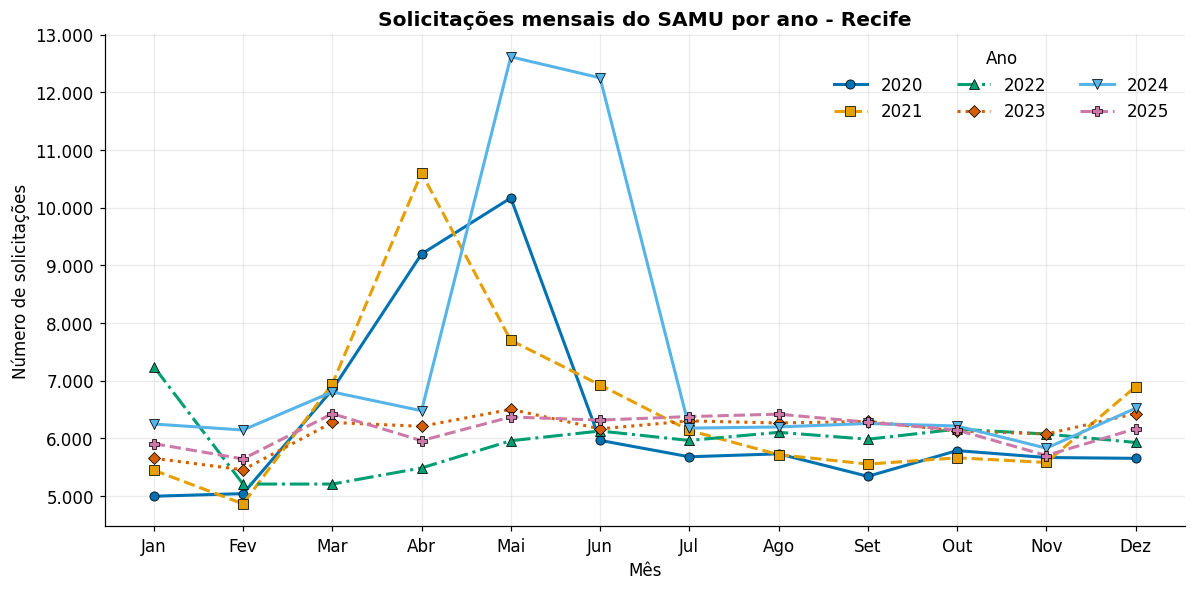

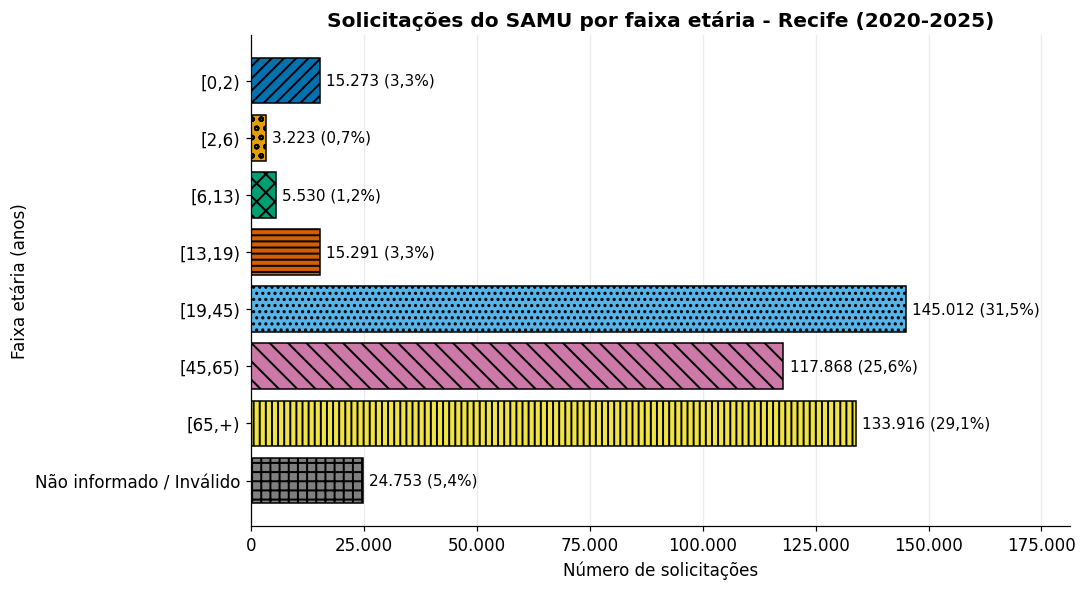

Gráficos salvos em: /content/samu/resultados


In [4]:
# ==========================================
# 3 GRÁFICOS - SAMU Recife (paleta acessível a daltônicos)
# Rode DEPOIS da célula de tratamento (usa df_final).
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Se o Colab foi reiniciado e df_final não existe, recarrega a base tratada
if 'df_final' not in globals():
    df_final = pd.read_csv('/content/samu/dados_tratados/samu_recife_tratado.csv',
                           low_memory=False, parse_dates=['data_trata'])

df = df_final.copy()
df['data_trata'] = pd.to_datetime(df['data_trata'], errors='coerce')
df['ano_arquivo'] = df['ano_arquivo'].astype(int)

PASTA = Path('/content/samu/resultados')
PASTA.mkdir(parents=True, exist_ok=True)

# Paleta Okabe-Ito (segura para os principais tipos de daltonismo)
AZUL, LARANJA, VERDE = '#0072B2', '#E69F00', '#009E73'
VERMELHO, CEU, ROSA, AMARELO = '#D55E00', '#56B4E9', '#CC79A7', '#F0E442'
CINZA = '#7F7F7F'

plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'axes.axisbelow': True,
    'font.size': 11, 'axes.titleweight': 'bold',
    'hatch.linewidth': 1.3,
})

# Cada barra recebe uma COR e um PADRÃO diferentes (linhas, bolas, xadrez...),
# no estilo dos gráficos acessíveis usados em publicações oficiais.
CORES_BARRAS = [AZUL, LARANJA, VERDE, VERMELHO, CEU, ROSA, AMARELO, CINZA]
PADROES = ['///', 'oo', 'xx', '---', '...', '\\\\', '|||', '++']


def milhar(x, _pos=None):
    return f'{x:,.0f}'.replace(',', '.')


# ------------------------------------------
# GRÁFICO 1 - Chamados por ano (colunas, rótulos nos valores)
# ------------------------------------------
por_ano = df.groupby('ano_arquivo').size()

fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(por_ano.index.astype(str), por_ano.values,
                color=CORES_BARRAS[:len(por_ano)], edgecolor='black', linewidth=1)
for b, h in zip(barras, PADROES):
    b.set_hatch(h)
for b in barras:
    ax.annotate(milhar(b.get_height()), (b.get_x() + b.get_width() / 2, b.get_height()),
                ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')
ax.set_title('Solicitações de atendimento do SAMU por ano - Recife')
ax.set_xlabel('Ano')
ax.set_ylabel('Número de solicitações')
ax.yaxis.set_major_formatter(plt.FuncFormatter(milhar))
ax.set_ylim(0, por_ano.max() * 1.12)
plt.tight_layout()
plt.savefig(PASTA / 'grafico1_chamados_por_ano.png', bbox_inches='tight')
plt.show()

# ------------------------------------------
# GRÁFICO 2 - Sazonalidade mensal por ano (linhas: cor + marcador + estilo)
# ------------------------------------------
mensal = (df.dropna(subset=['data_trata'])
            .assign(mes=lambda d: d['data_trata'].dt.month)
            .groupby(['ano_arquivo', 'mes']).size().unstack(0))

estilos = [
    (AZUL, 'o', '-'), (LARANJA, 's', '--'), (VERDE, '^', '-.'),
    (VERMELHO, 'D', ':'), (CEU, 'v', '-'), (ROSA, 'P', '--'),
]
meses = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

fig, ax = plt.subplots(figsize=(11, 5.5))
for (ano, serie), (cor, marc, ls) in zip(mensal.items(), estilos):
    ax.plot(serie.index, serie.values, color=cor, marker=marc, linestyle=ls,
            linewidth=2, markersize=6, markeredgecolor='black', markeredgewidth=0.5, label=str(ano))
ax.set_xticks(range(1, 13))
ax.set_xticklabels(meses)
ax.set_title('Solicitações mensais do SAMU por ano - Recife')
ax.set_xlabel('Mês')
ax.set_ylabel('Número de solicitações')
ax.yaxis.set_major_formatter(plt.FuncFormatter(milhar))
ax.legend(title='Ano', ncol=3, frameon=False)
plt.tight_layout()
plt.savefig(PASTA / 'grafico2_sazonalidade_mensal.png', bbox_inches='tight')
plt.show()

# ------------------------------------------
# GRÁFICO 3 - Solicitações por faixa etária (colunas horizontais, % nos rótulos)
# ------------------------------------------
ordem = ['[0,2)', '[2,6)', '[6,13)', '[13,19)', '[19,45)', '[45,65)', '[65,+)', 'Não informado / Inválido']
faixa = df['faixa_etaria'].value_counts().reindex(ordem).fillna(0)
total = faixa.sum()
barras_cores = CORES_BARRAS[:len(ordem)]

fig, ax = plt.subplots(figsize=(10, 5.5))
barras = ax.barh(faixa.index, faixa.values, color=barras_cores, edgecolor='black', linewidth=1)
for b, h in zip(barras, PADROES):
    b.set_hatch(h)
for b, v in zip(barras, faixa.values):
    pct = f'{v / total:.1%}'.replace('.', ',')
    ax.annotate(f'{milhar(v)} ({pct})',
                (v, b.get_y() + b.get_height() / 2), va='center', ha='left',
                fontsize=10, xytext=(4, 0), textcoords='offset points')
ax.invert_yaxis()
ax.set_title('Solicitações do SAMU por faixa etária - Recife (2020-2025)')
ax.set_xlabel('Número de solicitações')
ax.set_ylabel('Faixa etária (anos)')
ax.xaxis.set_major_formatter(plt.FuncFormatter(milhar))
ax.set_xlim(0, faixa.max() * 1.25)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.savefig(PASTA / 'grafico3_faixa_etaria.png', bbox_inches='tight')
plt.show()

print(f"Gráficos salvos em: {PASTA}")